In [1]:
import os
import pandas as pd
import kagglehub
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from IPython.display import display

## 1. Data Loading

In [2]:
path = kagglehub.dataset_download("redwankarimsony/heart-disease-data")

df = pd.read_csv(os.path.join(path, 'heart_disease_uci.csv'))

print(f"Dataset size: {len(df)} rows")
display(df.head())

Using Colab cache for faster access to the 'heart-disease-data' dataset.
Dataset size: 920 rows


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


## 2. Initial Exploration

In [3]:
df.describe()

,id,age,trestbps,chol,thalch,oldpeak,ca,num
count,920.000000,920.000000,861.000000,890.000000,865.000000,858.000000,309.000000,920.000000
mean,460.500000,53.510870,132.132404,199.130337,137.545665,0.878788,0.676375,0.995652
std,265.725422,9.424685,19.066070,110.780810,25.926276,1.091226,0.935653,1.142693
min,1.000000,28.000000,0.000000,0.000000,60.000000,-2.600000,0.000000,0.000000
25%,230.750000,47.000000,120.000000,175.000000,120.000000,0.000000,0.000000,0.000000
50%,460.500000,54.000000,130.000000,223.000000,140.000000,0.500000,0.000000,1.000000
75%,690.250000,60.000000,140.000000,268.000000,157.000000,1.500000,1.000000,2.000000
max,920.000000,77.000000,200.000000,603.000000,202.000000,6.200000,3.000000,4.000000


In [4]:
missing_by_dataset = df.groupby('dataset').apply(lambda x: x.isnull().sum(), include_groups=False)

print("Jumlah Missing Values per Fitur Berdasarkan Lokasi Dataset:")
display(missing_by_dataset)

Jumlah Missing Values per Fitur Berdasarkan Lokasi Dataset:


,id,age,sex,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
dataset,,,,,,,,,,,,,,,
Cleveland,0,0,0,0,0,0,0,0,0,0,0,1,5,3,0
Hungary,0,0,0,0,1,23,8,1,1,1,0,189,290,265,0
Switzerland,0,0,0,0,2,0,75,1,1,1,6,17,118,52,0
VA Long Beach,0,0,0,0,56,7,7,0,53,53,56,102,198,166,0


In [5]:
missing_percentage = df.groupby('dataset').apply(lambda x: (x.isnull().sum() / len(x)) * 100, include_groups=False)

print("Persentase Missing Values (%) per Fitur Berdasarkan Lokasi Dataset:")
display(missing_percentage.style.format("{:.2f}%").background_gradient(cmap='Reds'))

Persentase Missing Values (%) per Fitur Berdasarkan Lokasi Dataset:


,id,age,sex,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
dataset,,,,,,,,,,,,,,,
Cleveland,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%,0.33%,1.64%,0.99%,0.00%
Hungary,0.00%,0.00%,0.00%,0.00%,0.34%,7.85%,2.73%,0.34%,0.34%,0.34%,0.00%,64.51%,98.98%,90.44%,0.00%
Switzerland,0.00%,0.00%,0.00%,0.00%,1.63%,0.00%,60.98%,0.81%,0.81%,0.81%,4.88%,13.82%,95.93%,42.28%,0.00%
VA Long Beach,0.00%,0.00%,0.00%,0.00%,28.00%,3.50%,3.50%,0.00%,26.50%,26.50%,28.00%,51.00%,99.00%,83.00%,0.00%


In [6]:
categorical_cols = [col for col in df.select_dtypes(include=['object']).columns if col.lower() != 'id']

unique_values_data = []
for col in categorical_cols:
    unique_vals = df[col].unique().tolist()
    unique_values_data.append({
        'Nama Kolom': col,
        'Jumlah Unik': len(unique_vals),
        'Nilai Unik': ", ".join(map(str, unique_vals))
    })

df_unique = pd.DataFrame(unique_values_data)
print("Ringkasan Kolom Kategorikal:")
display(df_unique.style.set_properties(**{'text-align': 'left'}).set_table_styles([dict(selector='th', props=[('text-align', 'left')])]))

Ringkasan Kolom Kategorikal:


,Nama Kolom,Jumlah Unik,Nilai Unik
0,sex,2,"Male, Female"
1,dataset,4,"Cleveland, Hungary, Switzerland, VA Long Beach"
2,cp,4,"typical angina, asymptomatic, non-anginal, atypical angina"
3,fbs,3,"True, False, nan"
4,restecg,4,"lv hypertrophy, normal, st-t abnormality, nan"
5,exang,3,"False, True, nan"
6,slope,4,"downsloping, flat, upsloping, nan"
7,thal,4,"fixed defect, normal, reversable defect, nan"


## 3. Correlation Analysis & Feature Selection

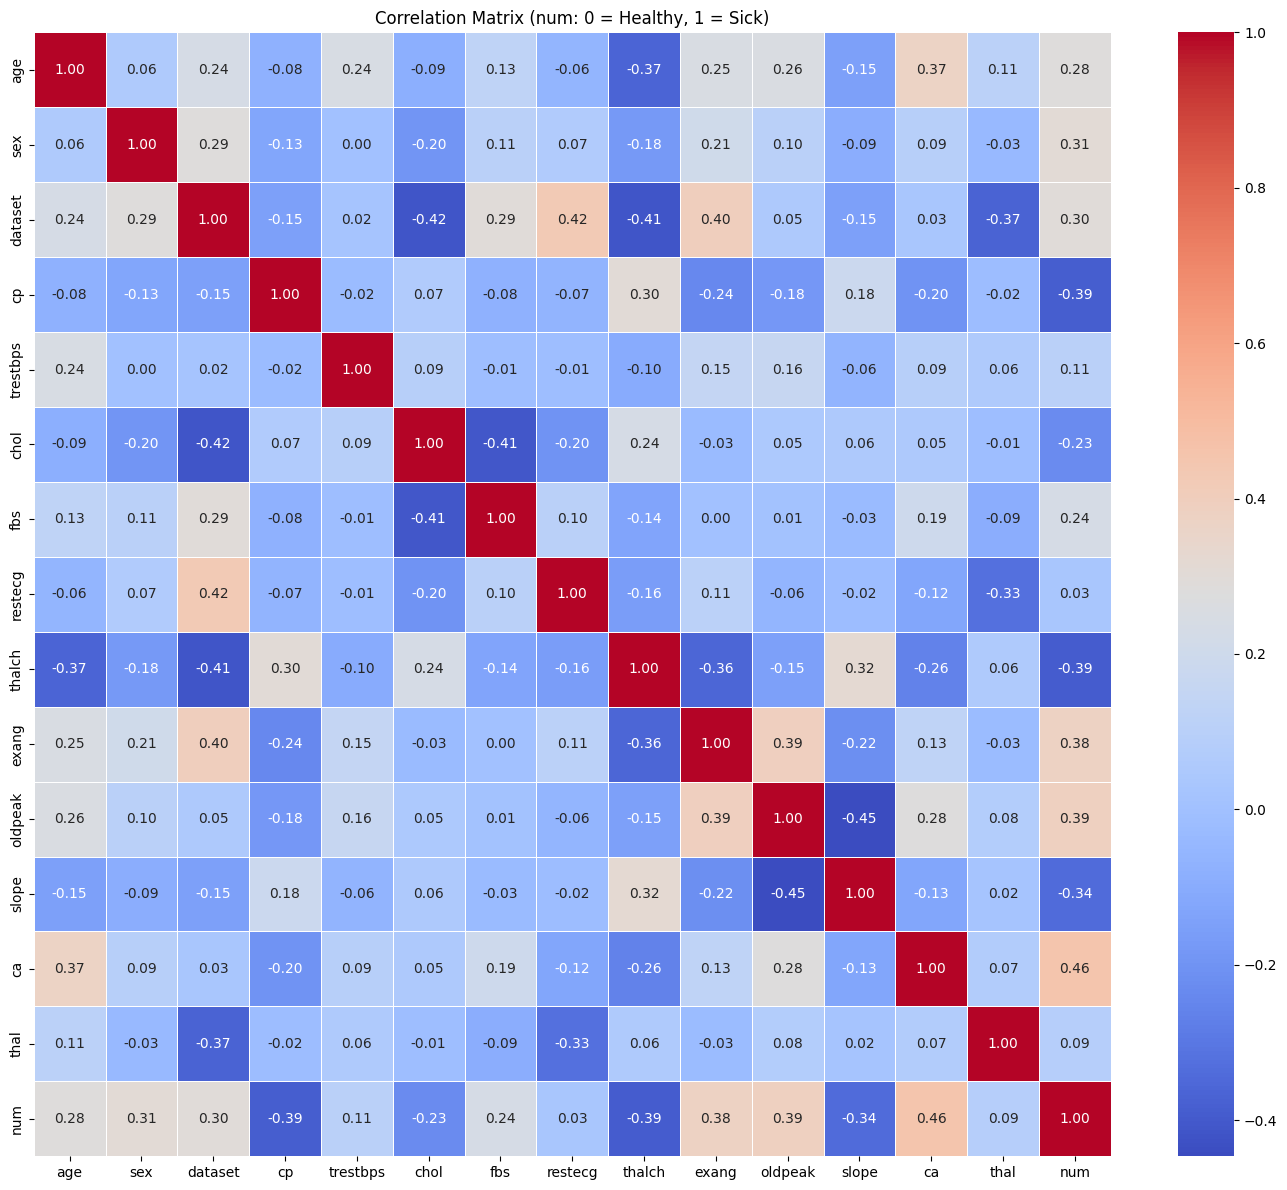

In [7]:
def encode_dataframe(df_input):
    """
    Encode categorical columns using LabelEncoder and
    binarize the target column 'num' (0 = Healthy, 1 = Sick).
    """
    df_encoded = df_input.copy()
    df_encoded['num'] = df_encoded['num'].apply(lambda x: 1 if x > 0 else 0)

    categorical_cols = df_encoded.select_dtypes(include=['object', 'bool']).columns
    le = LabelEncoder()
    for col in categorical_cols:
        df_encoded[col] = le.fit_transform(df_encoded[col].astype(str))

    return df_encoded


df_encoded = encode_dataframe(df)

correlation_matrix = df_encoded.drop(columns=['id']).corr()

plt.figure(figsize=(14, 12))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt=".2f",
    linewidths=0.5
)
plt.title('Correlation Matrix (num: 0 = Healthy, 1 = Sick)')
plt.tight_layout()
plt.show()

In [8]:
def evaluate_feature_priority(row):
    """
    Menentukan kategori fitur berdasarkan korelasi dan ketersediaan data.

    Args:
        row: Baris dari DataFrame feature_decision yang berisi nilai 'Korelasi'
             dan 'Max Missing (%)'.

    Returns:
        String status kategori fitur.
    """
    if row.name == 'num':
        return "Target"
    if row.name == 'dataset':
        return "ELIMINASI (Metadata)"

    if row['Max Missing (%)'] > 90:
        return "DROP (Missing > 90% in scope)"
    elif abs(row['Korelasi']) >= 0.3:
        return "PRIORITAS (Korelasi Kuat)"
    elif abs(row['Korelasi']) >= 0.1:
        return "PERTAHANKAN (Korelasi Lemah-Sedang)"
    else:
        return "ELIMINASI (Korelasi Sangat Rendah)"

target_datasets = ['Hungary', 'Switzerland', 'Cleveland']
df_target_scope = df[df['dataset'].isin(target_datasets)].copy()

missing_stats = df_target_scope.groupby('dataset').apply(
    lambda x: (x.isnull().sum() / len(x)) * 100,
    include_groups=False
)
max_missing = missing_stats.max().to_frame(name='Max Missing (%)')

corr_target = df_encoded.drop(columns=['id']).corr()['num'].to_frame(name='Korelasi')

feature_decision = corr_target.join(max_missing)
feature_decision['Keputusan'] = feature_decision.apply(evaluate_feature_priority, axis=1)

print("Analisis Final Pemilihan Fitur (Berdasarkan Kondisi Per Dataset):")
display_table = feature_decision[feature_decision.index != 'dataset']
display(display_table.sort_values(by='Max Missing (%)', ascending=False).style.format({
    'Korelasi': '{:.3f}',
    'Max Missing (%)': '{:.1f}%'
}).background_gradient(cmap='Reds', subset=['Max Missing (%)']))

Analisis Final Pemilihan Fitur (Berdasarkan Kondisi Per Dataset):


,Korelasi,Max Missing (%),Keputusan
ca,0.456,99.0%,DROP (Missing > 90% in scope)
thal,0.089,90.4%,DROP (Missing > 90% in scope)
slope,-0.340,64.5%,PRIORITAS (Korelasi Kuat)
fbs,0.236,61.0%,PERTAHANKAN (Korelasi Lemah-Sedang)
chol,-0.231,7.8%,PERTAHANKAN (Korelasi Lemah-Sedang)
oldpeak,0.386,4.9%,PRIORITAS (Korelasi Kuat)
trestbps,0.106,1.6%,PERTAHANKAN (Korelasi Lemah-Sedang)
exang,0.377,0.8%,PRIORITAS (Korelasi Kuat)
restecg,0.031,0.8%,ELIMINASI (Korelasi Sangat Rendah)
thalch,-0.395,0.8%,PRIORITAS (Korelasi Kuat)


In [9]:
SELECTED_FEATURES = ['oldpeak', 'thalch', 'exang', 'cp', 'sex', 'age', 'slope', 'chol', 'fbs', 'num']

print(f"\nFitur terpilih sesuai permintaan: {SELECTED_FEATURES}")


Fitur terpilih sesuai permintaan: ['oldpeak', 'thalch', 'exang', 'cp', 'sex', 'age', 'slope', 'chol', 'fbs', 'num']


### Analisis Korelasi & Rekomendasi Fitur Terperinci

Berdasarkan matriks korelasi terhadap target biner `num` (Sehat vs Sakit) dan analisis ketersediaan data per dataset:

#### Wawasan Utama (Insights):
- **Korelasi vs Realitas Data**: Meskipun `ca` memiliki korelasi tertinggi (0.46), fitur ini **dihapus** karena missing value mencapai >90% pada dataset Hungary dan Switzerland. Hal yang sama berlaku untuk `thal`.
- **Fitur Klinis Terkuat (Dipertahankan)**: `oldpeak` (0.39), `thalch` (-0.39), `cp` (-0.39), dan `exang` (0.38) menjadi pilar utama analisis karena korelasi kuat dan data yang relatif lengkap.
- **Demografi**: `sex` (0.31) menunjukkan pengaruh yang lebih signifikan dibandingkan `age` (0.28) dalam dataset ini.

#### Daftar Fitur Terpilih (Final Selection):
1.  **Prioritas Utama**: `cp`, `thalch`, `exang`, `oldpeak`, `sex`, `slope`.
2.  **Fitur Pendukung**: `age`, `trestbps`, `chol`, `fbs`.
3.  **Target**: `num`.

*Catatan: Fitur `ca` dan `thal` secara resmi dieliminasi dari alur kerja pemodelan untuk menjaga integritas dan fokus pada fitur klinis.*

In [10]:
target_locs = ['Cleveland', 'Hungary', 'Switzerland']

df_missing_check = df[df['dataset'].isin(target_locs)][['dataset'] + SELECTED_FEATURES]

missing_count_by_ds = df_missing_check.groupby('dataset').apply(lambda x: x.isnull().sum(), include_groups=False)

print(f"Jumlah Missing Value Berdasarkan Fitur Terpilih ({len(SELECTED_FEATURES)} fitur):")
display(missing_count_by_ds.style.background_gradient(cmap='Oranges'))

print("\nRingkasan total baris per dataset:")
print(df_missing_check['dataset'].value_counts())

Jumlah Missing Value Berdasarkan Fitur Terpilih (10 fitur):


,oldpeak,thalch,exang,cp,sex,age,slope,chol,fbs,num
dataset,,,,,,,,,,
Cleveland,0,0,0,0,0,0,1,0,0,0
Hungary,0,1,1,0,0,0,189,23,8,0
Switzerland,6,1,1,0,0,0,17,0,75,0



Ringkasan total baris per dataset:
dataset
Cleveland      304
Hungary        293
Switzerland    123
Name: count, dtype: int64


## 4. Target Distribution per Dataset

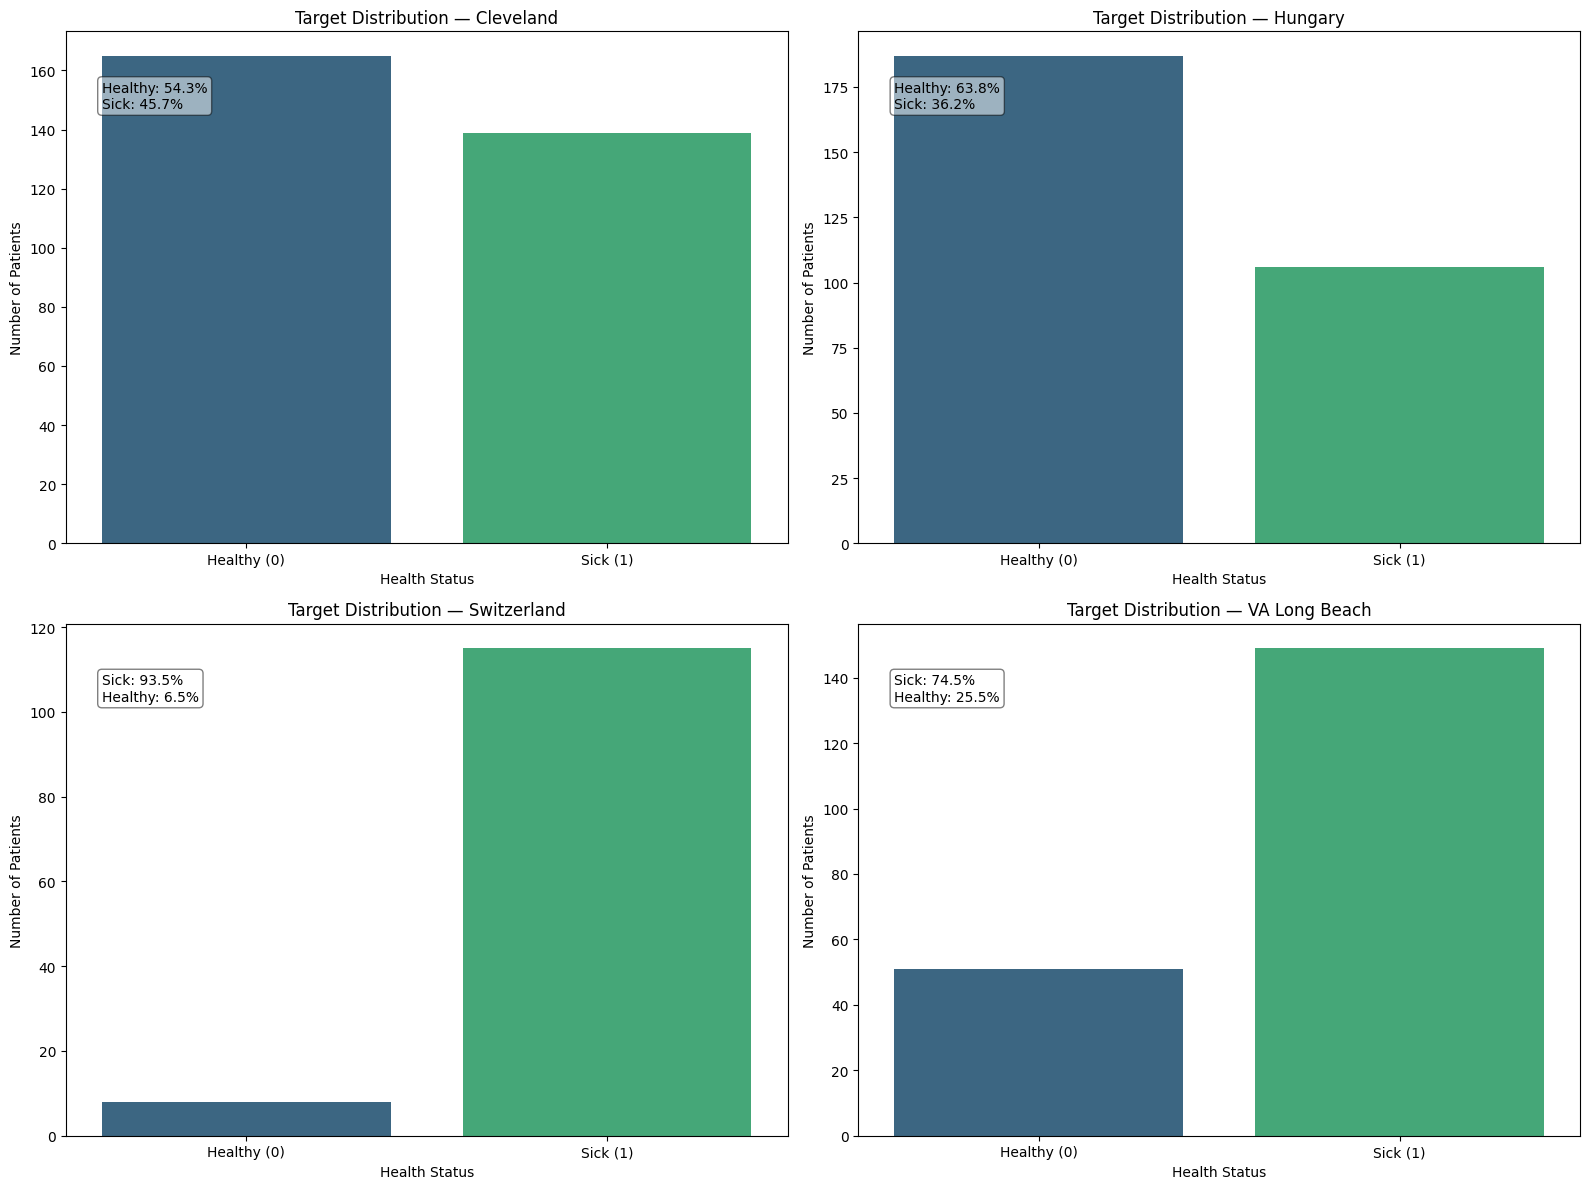

Target distribution percentage per dataset:


,Healthy (%),Sick (%)
dataset,,
Cleveland,54.276316,45.723684
Hungary,63.822526,36.177474
Switzerland,6.504065,93.495935
VA Long Beach,25.500000,74.500000


In [11]:
def plot_target_distribution(df_input):
    """
    Plot the distribution of binary target 'num' for each dataset location.
    """
    df_plot = df_input.copy()
    df_plot['target'] = df_plot['num'].apply(lambda x: 1 if x > 0 else 0)

    dataset_names = df_plot['dataset'].unique()
    plt.figure(figsize=(16, 12))

    for i, dataset_name in enumerate(dataset_names):
        plt.subplot(2, 2, i + 1)
        subset = df_plot[df_plot['dataset'] == dataset_name]
        counts = subset['target'].value_counts(normalize=True) * 100

        sns.countplot(
            data=subset,
            x='target',
            palette='viridis',
            hue='target',
            legend=False
        )
        plt.title(f'Target Distribution — {dataset_name}')
        plt.xlabel('Health Status')
        plt.ylabel('Number of Patients')
        plt.xticks([0, 1], ['Healthy (0)', 'Sick (1)'])

        annotation_text = "\n".join(
            [f"{['Healthy', 'Sick'][int(k)]}: {v:.1f}%" for k, v in counts.items()]
        )
        plt.annotate(
            annotation_text,
            xy=(0.05, 0.85),
            xycoords='axes fraction',
            bbox=dict(boxstyle='round', fc='white', alpha=0.5)
        )

    plt.tight_layout()
    plt.show()

    summary = pd.crosstab(df_plot['dataset'], df_plot['target'], normalize='index') * 100
    summary.columns = ['Healthy (%)', 'Sick (%)']
    print("Target distribution percentage per dataset:")
    display(summary)


plot_target_distribution(df)

### Non-IID Dataset Scheme Recommendation (2 Clients)

| Dataset     | Characteristic         | Reason                                      |
|-------------|------------------------|---------------------------------------------|
| Hungary     | Majority Healthy (63.8%) | Represents low disease prevalence          |
| Switzerland | Majority Sick (93.5%)    | Represents extreme high disease prevalence |

## 5. Non-IID Split: Hungary & Switzerland + Cleveland ( Centralized Eval )

In [12]:
df_hungary = df[df['dataset'] == 'Hungary'].copy()
print(f"Dataset Hungary size: {len(df_hungary)} rows")
display(df_hungary.head())

Dataset Hungary size: 293 rows


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
304,305,29,Male,Hungary,atypical angina,120.0,243.0,False,normal,160.0,False,0.0,NaN,NaN,NaN,0
305,306,29,Male,Hungary,atypical angina,140.0,NaN,False,normal,170.0,False,0.0,NaN,NaN,NaN,0
306,307,30,Female,Hungary,typical angina,170.0,237.0,False,st-t abnormality,170.0,False,0.0,NaN,NaN,fixed defect,0
307,308,31,Female,Hungary,atypical angina,100.0,219.0,False,st-t abnormality,150.0,False,0.0,NaN,NaN,NaN,0
308,309,32,Female,Hungary,atypical angina,105.0,198.0,False,normal,165.0,False,0.0,NaN,NaN,NaN,0


In [13]:
df_switzerland = df[df['dataset'] == 'Switzerland'].copy()
print(f"Dataset Switzerland size: {len(df_switzerland)} rows")
display(df_switzerland.head())

Dataset Switzerland size: 123 rows


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
597,598,32,Male,Switzerland,typical angina,95.0,0.0,NaN,normal,127.0,False,0.7,upsloping,NaN,NaN,1
598,599,34,Male,Switzerland,asymptomatic,115.0,0.0,NaN,NaN,154.0,False,0.2,upsloping,NaN,NaN,1
599,600,35,Male,Switzerland,asymptomatic,NaN,0.0,NaN,normal,130.0,True,NaN,NaN,NaN,reversable defect,3
600,601,36,Male,Switzerland,asymptomatic,110.0,0.0,NaN,normal,125.0,True,1.0,flat,NaN,fixed defect,1
601,602,38,Female,Switzerland,asymptomatic,105.0,0.0,NaN,normal,166.0,False,2.8,upsloping,NaN,NaN,2


In [14]:
df_cleveland = df[df['dataset'] == 'Cleveland'].copy()
print(f"Dataset Cleveland size: {len(df_cleveland)} rows")
display(df_cleveland.head())

Dataset Cleveland size: 304 rows


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


## 6. Feature Selection

In [15]:
df_hungary_selected = df_hungary[SELECTED_FEATURES].copy()
print(f"Dataset Hungary size: {len(df_hungary_selected)} rows")
display(df_hungary_selected.head())

Dataset Hungary size: 293 rows


,oldpeak,thalch,exang,cp,sex,age,slope,chol,fbs,num
304,0.0,160.0,False,atypical angina,Male,29,NaN,243.0,False,0
305,0.0,170.0,False,atypical angina,Male,29,NaN,NaN,False,0
306,0.0,170.0,False,typical angina,Female,30,NaN,237.0,False,0
307,0.0,150.0,False,atypical angina,Female,31,NaN,219.0,False,0
308,0.0,165.0,False,atypical angina,Female,32,NaN,198.0,False,0


In [16]:
df_switzerland_selected = df_switzerland[SELECTED_FEATURES].copy()
print(f"Dataset Switzerland size: {len(df_switzerland_selected)} rows")
display(df_switzerland_selected.head())

Dataset Switzerland size: 123 rows


,oldpeak,thalch,exang,cp,sex,age,slope,chol,fbs,num
597,0.7,127.0,False,typical angina,Male,32,upsloping,0.0,NaN,1
598,0.2,154.0,False,asymptomatic,Male,34,upsloping,0.0,NaN,1
599,NaN,130.0,True,asymptomatic,Male,35,NaN,0.0,NaN,3
600,1.0,125.0,True,asymptomatic,Male,36,flat,0.0,NaN,1
601,2.8,166.0,False,asymptomatic,Female,38,upsloping,0.0,NaN,2


In [17]:
df_cleveland_selected = df_cleveland[SELECTED_FEATURES].copy()
print(f"Dataset Cleveland size: {len(df_cleveland_selected)} rows")
display(df_cleveland_selected.head())

Dataset Cleveland size: 304 rows


,oldpeak,thalch,exang,cp,sex,age,slope,chol,fbs,num
0,2.3,150.0,False,typical angina,Male,63,downsloping,233.0,True,0
1,1.5,108.0,True,asymptomatic,Male,67,flat,286.0,False,2
2,2.6,129.0,True,asymptomatic,Male,67,flat,229.0,False,1
3,3.5,187.0,False,non-anginal,Male,37,downsloping,250.0,False,0
4,1.4,172.0,False,atypical angina,Female,41,upsloping,204.0,False,0


## 7. Missing Value Handling

In [18]:
def handle_missing_values(df_input):
    """
    Fill missing values:
    - Numerical columns: filled with column mean.
    - Categorical columns: filled with column mode.
    """
    df_clean = df_input.copy()

    numerical_cols = df_clean.select_dtypes(include=['float64', 'int64']).columns
    categorical_cols = df_clean.select_dtypes(include=['object', 'bool']).columns

    for col in numerical_cols:
        if df_clean[col].isnull().any():
            df_clean[col] = df_clean[col].fillna(df_clean[col].mean())

    for col in categorical_cols:
        if df_clean[col].isnull().any():
            mode_val = df_clean[col].dropna().mode()
            if not mode_val.empty:
                df_clean[col] = df_clean[col].fillna(mode_val[0])

    return df_clean

def get_missing_summary(df_before, df_after, name):
    """Menghitung perbandingan missing value sebelum dan sesudah penanganan."""
    before = df_before.isnull().sum()
    after = df_after.isnull().sum()
    summary = pd.DataFrame({'Before': before, 'After': after})
    summary.index.name = f'Fitur ({name})'
    return summary

In [19]:
pd.set_option('future.no_silent_downcasting', True)

df_hungary_cleaned = handle_missing_values(df_hungary_selected)

print("=== RINGKASAN PENANGANAN MISSING VALUE: HUNGARY ===")
display(get_missing_summary(df_hungary_selected, df_hungary_cleaned, "Hungary"))

hungary_sample_idx = df_hungary_selected[df_hungary_selected.isnull().any(axis=1)].head(3).index

print("\n=== SAMPEL DATA SEBELUM IMPUTASI (HUNGARY) ===")
display(df_hungary_selected.loc[hungary_sample_idx])

print("\n=== SAMPEL DATA SESUDAH IMPUTASI (HUNGARY) ===")
display(df_hungary_cleaned.loc[hungary_sample_idx])

=== RINGKASAN PENANGANAN MISSING VALUE: HUNGARY ===


,Before,After
Fitur (Hungary),,
oldpeak,0,0
thalch,1,0
exang,1,0
cp,0,0
sex,0,0
age,0,0
slope,189,0
chol,23,0
fbs,8,0



=== SAMPEL DATA SEBELUM IMPUTASI (HUNGARY) ===


Fitur (Hungary),oldpeak,thalch,exang,cp,sex,age,slope,chol,fbs,num
304,0.0,160.0,False,atypical angina,Male,29,NaN,243.0,False,0
305,0.0,170.0,False,atypical angina,Male,29,NaN,NaN,False,0
306,0.0,170.0,False,typical angina,Female,30,NaN,237.0,False,0



=== SAMPEL DATA SESUDAH IMPUTASI (HUNGARY) ===


,oldpeak,thalch,exang,cp,sex,age,slope,chol,fbs,num
304,0.0,160.0,False,atypical angina,Male,29,flat,243.000000,False,0
305,0.0,170.0,False,atypical angina,Male,29,flat,251.288889,False,0
306,0.0,170.0,False,typical angina,Female,30,flat,237.000000,False,0


In [20]:
df_switzerland_cleaned = handle_missing_values(df_switzerland_selected)

print("=== RINGKASAN PENANGANAN MISSING VALUE: SWITZERLAND ===")
display(get_missing_summary(df_switzerland_selected, df_switzerland_cleaned, "Switzerland"))

switzerland_sample_idx = df_switzerland_selected[df_switzerland_selected.isnull().any(axis=1)].head(5).index

print("\n=== SAMPEL DATA SEBELUM IMPUTASI (SWITZERLAND) ===")
display(df_switzerland_selected.loc[switzerland_sample_idx])

print("\n=== SAMPEL DATA SESUDAH IMPUTASI (SWITZERLAND) ===")
display(df_switzerland_cleaned.loc[switzerland_sample_idx])

=== RINGKASAN PENANGANAN MISSING VALUE: SWITZERLAND ===


,Before,After
Fitur (Switzerland),,
oldpeak,6,0
thalch,1,0
exang,1,0
cp,0,0
sex,0,0
age,0,0
slope,17,0
chol,0,0
fbs,75,0



=== SAMPEL DATA SEBELUM IMPUTASI (SWITZERLAND) ===


Fitur (Switzerland),oldpeak,thalch,exang,cp,sex,age,slope,chol,fbs,num
597,0.7,127.0,False,typical angina,Male,32,upsloping,0.0,NaN,1
598,0.2,154.0,False,asymptomatic,Male,34,upsloping,0.0,NaN,1
599,NaN,130.0,True,asymptomatic,Male,35,NaN,0.0,NaN,3
600,1.0,125.0,True,asymptomatic,Male,36,flat,0.0,NaN,1
601,2.8,166.0,False,asymptomatic,Female,38,upsloping,0.0,NaN,2



=== SAMPEL DATA SESUDAH IMPUTASI (SWITZERLAND) ===


,oldpeak,thalch,exang,cp,sex,age,slope,chol,fbs,num
597,0.700000,127.0,False,typical angina,Male,32,upsloping,0.0,False,1
598,0.200000,154.0,False,asymptomatic,Male,34,upsloping,0.0,False,1
599,0.653846,130.0,True,asymptomatic,Male,35,flat,0.0,False,3
600,1.000000,125.0,True,asymptomatic,Male,36,flat,0.0,False,1
601,2.800000,166.0,False,asymptomatic,Female,38,upsloping,0.0,False,2


In [21]:
df_cleveland_cleaned = handle_missing_values(df_cleveland_selected)

print("=== RINGKASAN PENANGANAN MISSING VALUE: CLEVELAND ===")
display(get_missing_summary(df_cleveland_selected, df_cleveland_cleaned, "Cleveland"))

cleveland_sample_idx = df_cleveland_selected[df_cleveland_selected.isnull().any(axis=1)].head(5).index

if not cleveland_sample_idx.empty:
    print("\n=== SAMPEL DATA SEBELUM IMPUTASI (CLEVELAND) ===")
    display(df_cleveland_selected.loc[cleveland_sample_idx])

    print("\n=== SAMPEL DATA SESUDAH IMPUTASI (CLEVELAND) ===")
    display(df_cleveland_cleaned.loc[cleveland_sample_idx])
else:
    print("\nInfo: Tidak ditemukan missing value pada sampel dataset Cleveland.")

=== RINGKASAN PENANGANAN MISSING VALUE: CLEVELAND ===


,Before,After
Fitur (Cleveland),,
oldpeak,0,0
thalch,0,0
exang,0,0
cp,0,0
sex,0,0
age,0,0
slope,1,0
chol,0,0
fbs,0,0



=== SAMPEL DATA SEBELUM IMPUTASI (CLEVELAND) ===


Fitur (Cleveland),oldpeak,thalch,exang,cp,sex,age,slope,chol,fbs,num
303,0.0,185.0,False,atypical angina,Male,28,NaN,132.0,False,0



=== SAMPEL DATA SESUDAH IMPUTASI (CLEVELAND) ===


,oldpeak,thalch,exang,cp,sex,age,slope,chol,fbs,num
303,0.0,185.0,False,atypical angina,Male,28,upsloping,132.0,False,0


## 8. Label Encoding

In [22]:
CATEGORICAL_ENCODE_COLS = [col for col in df_hungary_cleaned.columns if df_hungary_cleaned[col].dtype == 'object' and col in SELECTED_FEATURES]

def apply_label_encoding(df_input, columns):
    """Apply LabelEncoder to specified categorical columns and binary target."""
    df_encoded = df_input.copy()

    le = LabelEncoder()
    for col in columns:
        if col in df_encoded.columns:
            df_encoded[col] = le.fit_transform(df_encoded[col].astype(str))
    return df_encoded

def process_and_display_encoding(df_cleaned, name, categorical_cols):
    """Menerapkan encoding dan menampilkan perbandingan Before vs After."""
    print(f"\n=== LABEL ENCODING: {name.upper()} ===")

    sample_idx = df_cleaned.head(5).index

    print(f"\n[ {name} ] Sampel Sebelum Encoding:")
    display(df_cleaned.loc[sample_idx, categorical_cols])

    df_encoded = apply_label_encoding(df_cleaned, categorical_cols)

    print(f"\n[ {name} ] Sampel Sesudah Encoding:")
    display(df_encoded.loc[sample_idx, categorical_cols])

    return df_encoded

In [23]:
df_hungary_encoded = process_and_display_encoding(df_hungary_cleaned, "Hungary", CATEGORICAL_ENCODE_COLS)


=== LABEL ENCODING: HUNGARY ===

[ Hungary ] Sampel Sebelum Encoding:


,exang,cp,sex,slope,fbs
304,False,atypical angina,Male,flat,False
305,False,atypical angina,Male,flat,False
306,False,typical angina,Female,flat,False
307,False,atypical angina,Female,flat,False
308,False,atypical angina,Female,flat,False



[ Hungary ] Sampel Sesudah Encoding:


,exang,cp,sex,slope,fbs
304,0,1,1,1,0
305,0,1,1,1,0
306,0,3,0,1,0
307,0,1,0,1,0
308,0,1,0,1,0


In [24]:
df_switzerland_encoded = process_and_display_encoding(df_switzerland_cleaned, "Switzerland", CATEGORICAL_ENCODE_COLS)


=== LABEL ENCODING: SWITZERLAND ===

[ Switzerland ] Sampel Sebelum Encoding:


,exang,cp,sex,slope,fbs
597,False,typical angina,Male,upsloping,False
598,False,asymptomatic,Male,upsloping,False
599,True,asymptomatic,Male,flat,False
600,True,asymptomatic,Male,flat,False
601,False,asymptomatic,Female,upsloping,False



[ Switzerland ] Sampel Sesudah Encoding:


,exang,cp,sex,slope,fbs
597,0,3,1,2,0
598,0,0,1,2,0
599,1,0,1,1,0
600,1,0,1,1,0
601,0,0,0,2,0


In [25]:
df_cleveland_encoded = process_and_display_encoding(df_cleveland_cleaned, "Cleveland", CATEGORICAL_ENCODE_COLS)


=== LABEL ENCODING: CLEVELAND ===

[ Cleveland ] Sampel Sebelum Encoding:


,exang,cp,sex,slope,fbs
0,False,typical angina,Male,downsloping,True
1,True,asymptomatic,Male,flat,False
2,True,asymptomatic,Male,flat,False
3,False,non-anginal,Male,downsloping,False
4,False,atypical angina,Female,upsloping,False



[ Cleveland ] Sampel Sesudah Encoding:


,exang,cp,sex,slope,fbs
0,0,3,1,0,1
1,1,0,1,1,0
2,1,0,1,1,0
3,0,2,1,0,0
4,0,1,0,2,0


## 9. Label Binarization

In [26]:
def binarize_and_display(df_input, name):
    """Mengubah target num menjadi biner dan menampilkan Before vs After secara berdampingan."""
    print(f"\n=== BINARY LABELING (TARGET 'num'): {name.upper()} ===")

    df_binarized = df_input.copy()
    sample_idx = df_binarized.head(5).index

    df_before = df_input.loc[sample_idx, ['num']].copy()

    df_binarized['num'] = df_binarized['num'].apply(lambda x: 1 if x >= 1 else 0)
    df_after = df_binarized.loc[sample_idx, ['num']].copy()

    comparison = pd.concat([df_before.add_suffix('_Before'), df_after.add_suffix('_After')], axis=1)
    display(comparison)

    return df_binarized

In [27]:
df_hungary_bin = binarize_and_display(df_hungary_encoded, "Hungary")


=== BINARY LABELING (TARGET 'num'): HUNGARY ===


,num_Before,num_After
304,0,0
305,0,0
306,0,0
307,0,0
308,0,0


In [28]:
df_switzerland_bin = binarize_and_display(df_switzerland_encoded, "Switzerland")


=== BINARY LABELING (TARGET 'num'): SWITZERLAND ===


,num_Before,num_After
597,1,1
598,1,1
599,3,1
600,1,1
601,2,1


In [29]:
df_cleveland_bin = binarize_and_display(df_cleveland_encoded, "Cleveland")


=== BINARY LABELING (TARGET 'num'): CLEVELAND ===


,num_Before,num_After
0,0,0
1,2,1
2,1,1
3,0,0
4,0,0


## 10. Feature Normalization

In [30]:
NUMERICAL_SCALE_COLS = [col for col in df_hungary_bin.columns if df_hungary_bin[col].dtype != 'object' and col != 'num']

def apply_standard_scaling(df_input, columns):
    df_scaled = df_input.copy()
    scaler = StandardScaler()
    df_scaled[columns] = scaler.fit_transform(df_scaled[columns])
    return df_scaled

def process_and_display_scaling(df_bin, name, columns):
    print(f"\n=== FEATURE SCALING (StandardScaler): {name.upper()} ===")

    stats_before = df_bin[columns].agg(['mean', 'std']).T

    df_final = apply_standard_scaling(df_bin, columns)

    stats_after = df_final[columns].agg(['mean', 'std']).T

    comparison = pd.concat([
        stats_before.add_suffix('_Before'),
        stats_after.add_suffix('_After')
    ], axis=1)

    comparison.index.name = 'Fitur'

    print(f"\nStatistik Deskriptif {name}:")
    display(comparison.style.format("{:.2f}"))

    return df_final

In [31]:
df_hungary_final = process_and_display_scaling(df_hungary_bin, "Hungary", NUMERICAL_SCALE_COLS)


=== FEATURE SCALING (StandardScaler): HUNGARY ===

Statistik Deskriptif Hungary:


,mean_Before,std_Before,mean_After,std_After
Fitur,,,,
oldpeak,0.59,0.91,0.00,1.00
thalch,138.97,23.44,-0.00,1.00
exang,0.30,0.46,-0.00,1.00
cp,0.84,0.86,0.00,1.00
sex,0.72,0.45,0.00,1.00
age,47.89,7.74,0.00,1.00
slope,1.04,0.21,0.00,1.00
chol,251.29,64.68,0.00,1.00
fbs,0.07,0.25,0.00,1.00


In [32]:
df_switzerland_final = process_and_display_scaling(df_switzerland_bin, "Switzerland", NUMERICAL_SCALE_COLS)


=== FEATURE SCALING (StandardScaler): SWITZERLAND ===

Statistik Deskriptif Switzerland:


,mean_Before,std_Before,mean_After,std_After
Fitur,,,,
oldpeak,0.65,1.03,0.00,1.00
thalch,121.56,25.87,0.00,1.00
exang,0.44,0.50,0.00,1.00
cp,0.41,0.85,0.00,1.00
sex,0.92,0.27,-0.00,1.00
age,55.32,9.03,-0.00,1.00
slope,1.17,0.58,0.00,1.00
chol,0.00,0.00,0.00,0.00
fbs,0.04,0.20,-0.00,1.00


In [33]:
df_cleveland_final = process_and_display_scaling(df_cleveland_bin, "Cleveland", NUMERICAL_SCALE_COLS)


=== FEATURE SCALING (StandardScaler): CLEVELAND ===

Statistik Deskriptif Cleveland:


,mean_Before,std_Before,mean_After,std_After
Fitur,,,,
oldpeak,1.04,1.16,0.00,1.00
thalch,149.72,22.93,-0.00,1.00
exang,0.33,0.47,0.00,1.00
cp,0.96,1.03,0.00,1.00
sex,0.68,0.47,-0.00,1.00
age,54.35,9.15,-0.00,1.00
slope,1.40,0.62,-0.00,1.00
chol,246.32,52.11,-0.00,1.00
fbs,0.15,0.36,0.00,1.00


## 11. Export Cleaned Datasets

In [34]:
HUNGARY_OUTPUT_PATH = 'heart_disease_hungary_cleaned.csv'
SWITZERLAND_OUTPUT_PATH = 'heart_disease_switzerland_cleaned.csv'
CLEVELAND_OUTPUT_PATH = 'heart_disease_cleveland_cleaned.csv'

df_hungary_final.to_csv(HUNGARY_OUTPUT_PATH, index=False)
df_switzerland_final.to_csv(SWITZERLAND_OUTPUT_PATH, index=False)
df_cleveland_final.to_csv(CLEVELAND_OUTPUT_PATH, index=False)

print(f"Files saved successfully:")
print(f"  1. {HUNGARY_OUTPUT_PATH}")
print(f"  2. {SWITZERLAND_OUTPUT_PATH}")
print(f"  3. {CLEVELAND_OUTPUT_PATH}")

Files saved successfully:
  1. heart_disease_hungary_cleaned.csv
  2. heart_disease_switzerland_cleaned.csv
  3. heart_disease_cleveland_cleaned.csv
